## Imports

In [1]:
import copy
import itertools
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")  

Selected device: cuda
GPU: Tesla T4


In [3]:
DATA_DIR = "/kaggle/input"
DATA_VARIANT = "full"  

DATA_FILES = {
    "full": "diabetes_binary_health_indicators_BRFSS2015.csv",
    "5050": "diabetes_binary_5050split_health_indicators_BRFSS2015.csv",
}
EXPECTED_ROWS = {"full": 253_680, "5050": 70_692}

TARGET = "Diabetes_binary"
CLASS_NAMES = ["No Diabetes", "Diabetes"]
CONTINUOUS_FEATURES = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]

USE_CLASS_WEIGHTS = True
LEARNING_RATE = 0.01
EPOCHS = 400

## Load Dataset

In [4]:
def load_dataset():
    matches = list(Path(DATA_DIR).rglob(DATA_FILES[DATA_VARIANT]))
    if not matches:
        found = sorted(p.name for p in Path(DATA_DIR).rglob("*.csv"))
        raise FileNotFoundError(
            f"{DATA_FILES[DATA_VARIANT]} not found under {DATA_DIR}.\n"
            f"CSV files available: {found}\n"
            "Fix DATA_FILES in the config cell, or add the dataset via Add Input."
        )
    print("Loaded from:", matches[0])
    return pd.read_csv(matches[0])


df = load_dataset()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Loaded from: /kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv
Dataset loaded successfully!
Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


##Verifiy Dataset

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 253680
Number of columns: 22

Column names:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Data types:
Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Educati

In [6]:
EXPECTED_COLUMNS = {
    TARGET, "HighBP", "HighChol", "CholCheck", "BMI", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth", "MentHlth", "PhysHlth", "DiffWalk",
    "Sex", "Age", "Education", "Income",
}

missing, extra = EXPECTED_COLUMNS - set(df.columns), set(df.columns) - EXPECTED_COLUMNS
assert not missing and not extra, f"Missing: {missing} | Unexpected: {extra}"
assert df.shape == (EXPECTED_ROWS[DATA_VARIANT], 22), f"Unexpected shape: {df.shape}"
assert df[TARGET].isin([0, 1]).all(), "Invalid target values!"

print("All initial dataset checks passed!")

All initial dataset checks passed!


## EDA

In [7]:
# Basic dataset information
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (253680, 22)

Data Types:
Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [8]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing Count,Missing Percentage
Diabetes_binary,0,0.0
HighBP,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0
Smoker,0,0.0
Stroke,0,0.0
HeartDiseaseorAttack,0,0.0
PhysActivity,0,0.0
Fruits,0,0.0


In [9]:
feature_columns = [c for c in df.columns if c != TARGET]

exact_duplicates = df.duplicated().sum()
duplicate_feature_rows = df.duplicated(subset=feature_columns, keep=False).sum()
conflicting_groups = int((df.groupby(feature_columns)[TARGET].nunique() > 1).sum())

print("Exact duplicate rows:", exact_duplicates)
print("Rows in duplicate feature combinations:", duplicate_feature_rows)
print("Feature groups with conflicting labels:", conflicting_groups)

Exact duplicate rows: 24206
Rows in duplicate feature combinations: 38000
Feature groups with conflicting labels: 1566


Class counts:
 Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Class percentages:
 Diabetes_binary
0.0    86.07
1.0    13.93
Name: count, dtype: float64


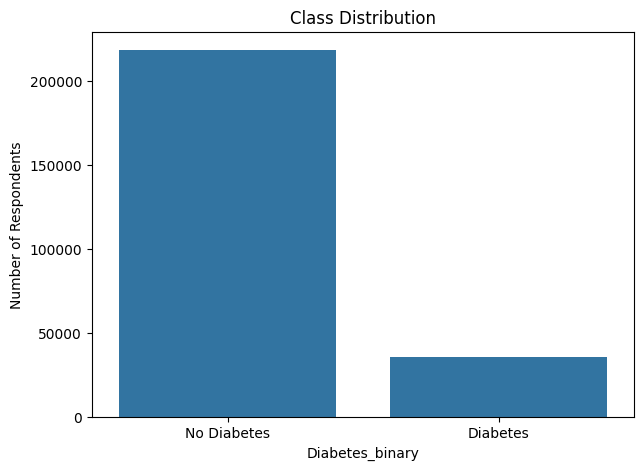

In [10]:
target_counts = df[TARGET].value_counts().sort_index()
print("Class counts:\n", target_counts)
print("\nClass percentages:\n", (target_counts / len(df) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=TARGET)
plt.xticks([0, 1], CLASS_NAMES)
plt.title("Class Distribution")
plt.ylabel("Number of Respondents")
plt.show()

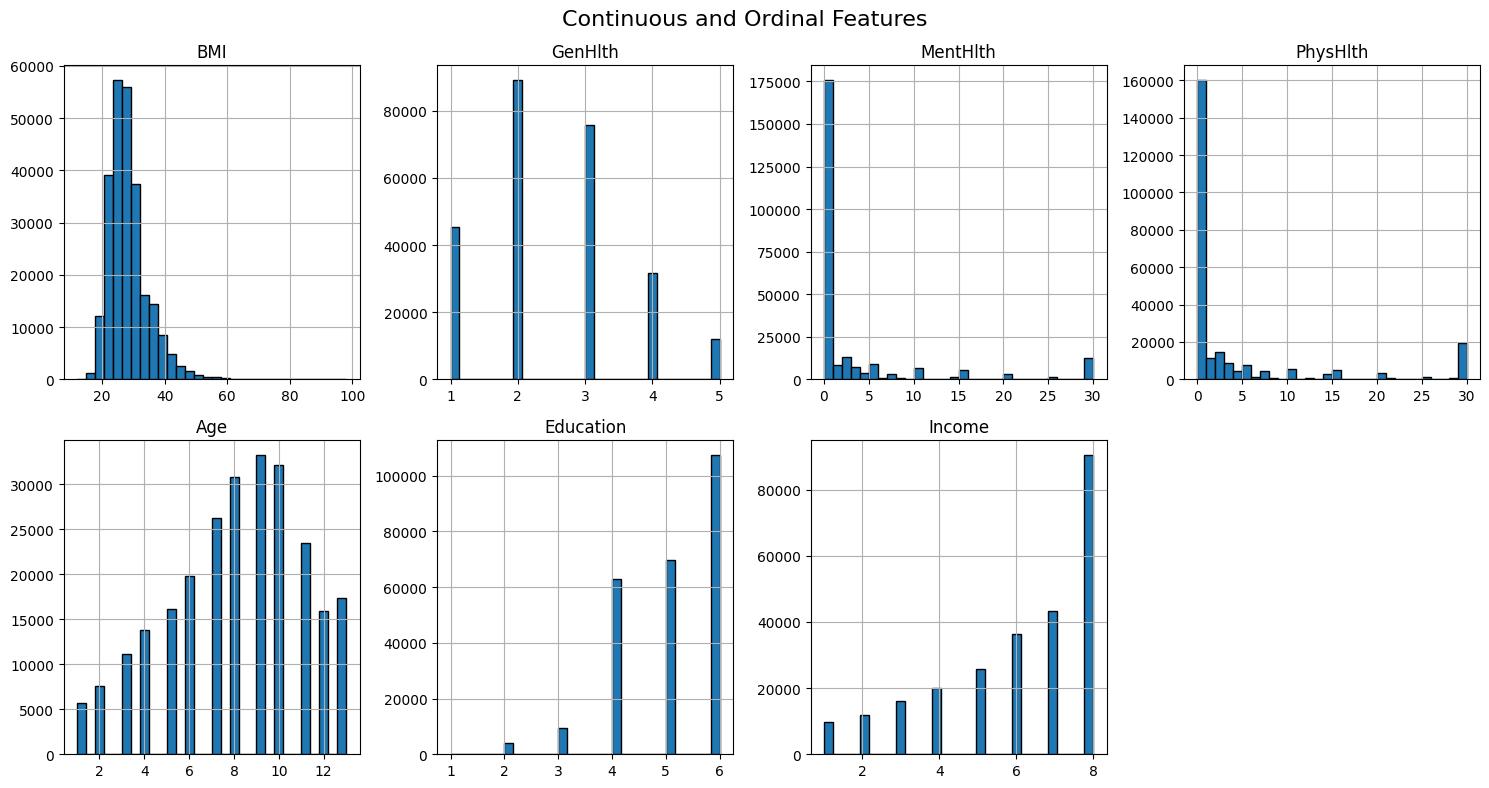

In [11]:
BINARY_FEATURES = [c for c in df.columns if c not in CONTINUOUS_FEATURES + [TARGET]]

df[CONTINUOUS_FEATURES].hist(figsize=(15, 8), bins=30, edgecolor="black", layout=(2, 4))
plt.suptitle("Continuous and Ordinal Features", fontsize=16)
plt.tight_layout()
plt.show()

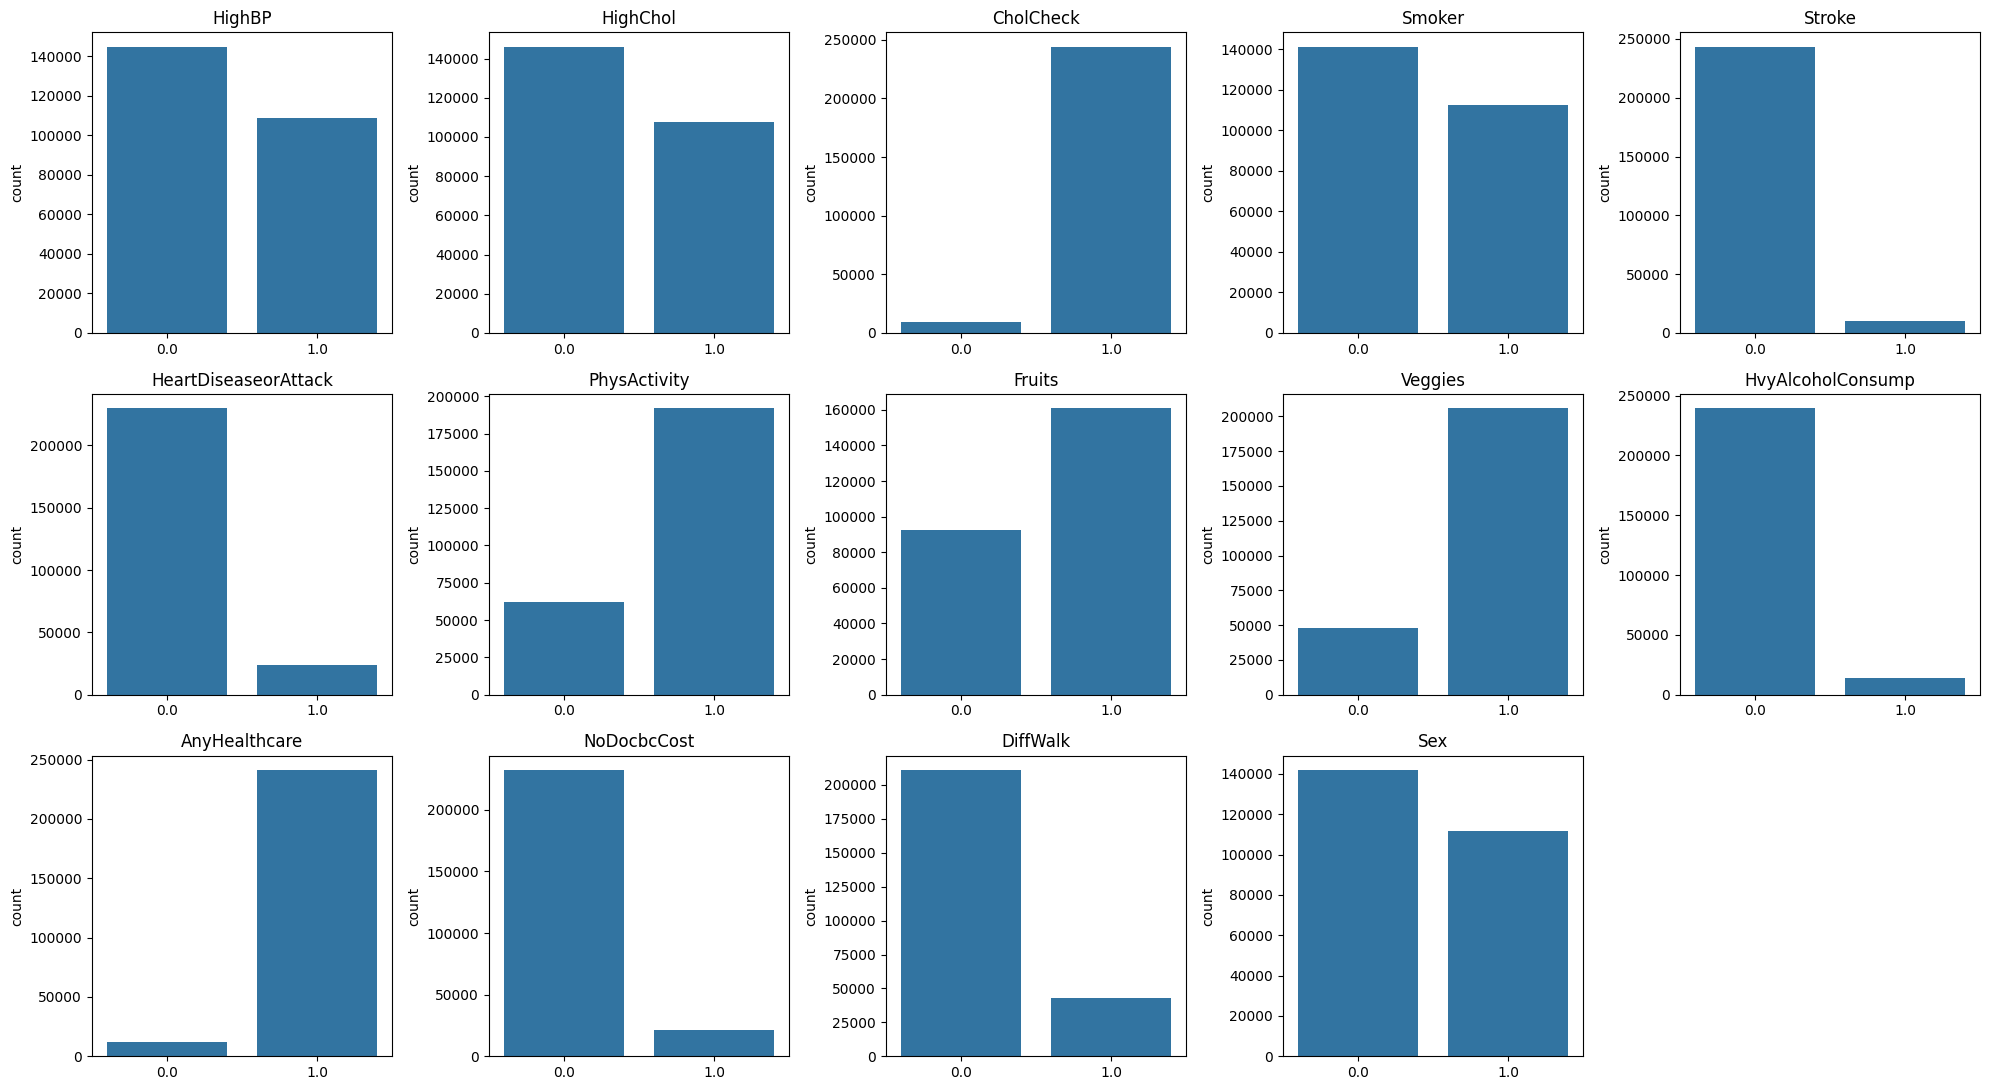

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
axes = axes.flatten()

for feature, ax in zip(BINARY_FEATURES, axes):
    sns.countplot(data=df, x=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")

for ax in axes[len(BINARY_FEATURES):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

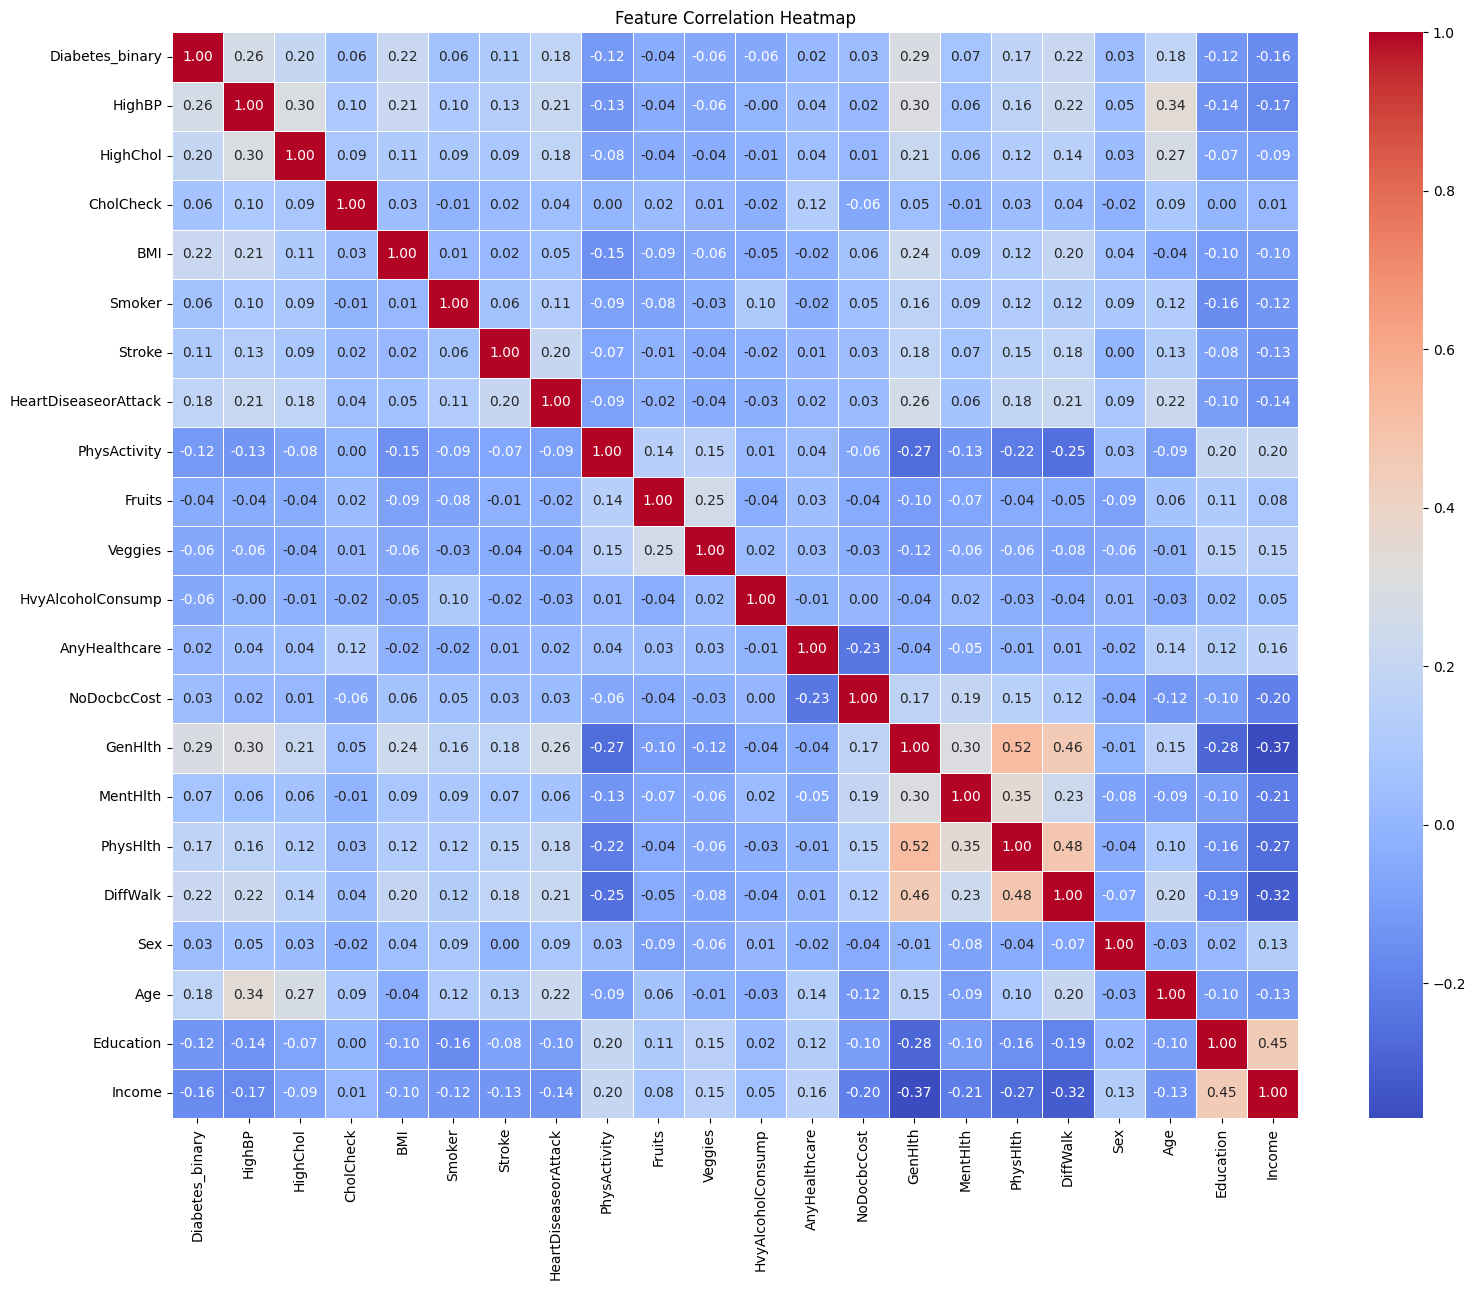

In [13]:
plt.figure(figsize=(16, 13))

correlation = correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

##Preprocess (Cleaning)

In [14]:
assert df.isnull().sum().sum() == 0, "Unexpected missing values"

df_clean = df.astype({TARGET: int}).reset_index(drop=True)

print("Original shape:", df.shape)
print("Cleaned shape: ", df_clean.shape)

Original shape: (253680, 22)
Cleaned shape:  (253680, 22)


In [15]:
assert df_clean.shape == df.shape
assert df_clean[TARGET].isin([0, 1]).all()
assert df_clean.isnull().sum().sum() == 0

print("Dataset verification passed!")
print((df_clean[TARGET].value_counts(normalize=True) * 100).round(2))
display(df_clean.describe().T)

Dataset verification passed!
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


##Data Splitting

In [16]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate predictors and target
X = df_clean.drop(columns=[TARGET]).astype("float64")
y = df_clean[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (253680, 21)
Target shape: (253680,)

Input features:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target distribution:
Diabetes_binary
0    86.066698
1    13.933302
Name: proportion, dtype: float64


In [17]:
# Each unique feature combination receives a group ID
groups = X.groupby(list(X.columns), sort=False).ngroup().to_numpy()

print("Total records:", len(X))
print("Unique feature groups:", len(np.unique(groups)))
print("Duplicate records:", len(X) - len(np.unique(groups)))

Total records: 253680
Unique feature groups: 227908
Duplicate records: 25772


In [18]:
sgkf_1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    sgkf_1.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_temp = X.iloc[temp_idx].copy()

y_train = y.iloc[train_idx].copy()
y_temp = y.iloc[temp_idx].copy()

groups_train = groups[train_idx]
groups_temp = groups[temp_idx]

print("Training set:", X_train.shape)
print("Temporary set:", X_temp.shape)

Training set: (202779, 21)
Temporary set: (50901, 21)


In [19]:
sgkf_2 = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    sgkf_2.split(X_temp, y_temp, groups_temp)
)

X_val = X_temp.iloc[val_idx].copy()
X_test = X_temp.iloc[test_idx].copy()

y_val = y_temp.iloc[val_idx].copy()
y_test = y_temp.iloc[test_idx].copy()

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (202779, 21)
Validation set: (25342, 21)
Test set: (25559, 21)


In [20]:
total = len(df_clean)

splits = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for name, (features, target) in splits.items():
    print(f"\n{name} Set")
    print("-" * 35)
    print("Records:", len(features))
    print("Percentage:", round(len(features) / total * 100, 2), "%")
    print("Class distribution:")
    print(target.value_counts(normalize=True).sort_index() * 100)


Training Set
-----------------------------------
Records: 202779
Percentage: 79.93 %
Class distribution:
Diabetes_binary
0    85.967482
1    14.032518
Name: proportion, dtype: float64

Validation Set
-----------------------------------
Records: 25342
Percentage: 9.99 %
Class distribution:
Diabetes_binary
0    86.374398
1    13.625602
Name: proportion, dtype: float64

Test Set
-----------------------------------
Records: 25559
Percentage: 10.08 %
Class distribution:
Diabetes_binary
0    86.54877
1    13.45123
Name: proportion, dtype: float64


In [21]:
train_groups = set(groups_train)

val_groups = set(groups_temp[val_idx])
test_groups = set(groups_temp[test_idx])

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0

print("\nNo group leakage detected!")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

No group leakage detected!


In [22]:
assert len(X_train) + len(X_val) + len(X_test) == len(df_clean)

assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

print("All splitting checks passed!")

All splitting checks passed!


In [23]:
from sklearn.preprocessing import StandardScaler

continuous_features = CONTINUOUS_FEATURES

scaler = StandardScaler()

# Fit ONLY on training data
X_train.loc[:, continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

# Transform validation and test using training statistics
X_val.loc[:, continuous_features] = scaler.transform(
    X_val[continuous_features]
)

X_test.loc[:, continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Standardization completed!")

Standardization completed!


In [24]:
print("Training means:")
display(X_train[continuous_features].mean())

print("\nTraining standard deviations:")
display(X_train[continuous_features].std(ddof=0))

print("\nValidation means:")
display(X_val[continuous_features].mean())

print("\nTest means:")
display(X_test[continuous_features].mean())

Training means:


BMI          1.387594e-16
GenHlth      9.418820e-17
MentHlth     2.803220e-18
PhysHlth     4.485152e-17
Age         -1.132501e-16
Education    4.238469e-16
Income       1.659506e-16
dtype: float64


Training standard deviations:


BMI          1.0
GenHlth      1.0
MentHlth     1.0
PhysHlth     1.0
Age          1.0
Education    1.0
Income       1.0
dtype: float64


Validation means:


BMI         -0.009222
GenHlth      0.002066
MentHlth     0.003407
PhysHlth    -0.002657
Age         -0.002992
Education   -0.007431
Income       0.006860
dtype: float64


Test means:


BMI         -0.011926
GenHlth     -0.013141
MentHlth    -0.002725
PhysHlth    -0.004723
Age          0.000338
Education    0.013069
Income       0.018061
dtype: float64

In [25]:
# Convert features to NumPy arrays
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Convert targets to integer arrays
y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_np, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_np, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_np, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.long)

print("Tensor conversion completed!")

print("\nTraining:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

Tensor conversion completed!

Training: torch.Size([202779, 21]) torch.Size([202779])
Validation: torch.Size([25342, 21]) torch.Size([25342])
Testing: torch.Size([25559, 21]) torch.Size([25559])


In [26]:
# Check whether identical feature sets have conflicting target labels
label_conflicts = (
    df_clean.groupby(X.columns.tolist(), dropna=False)[TARGET]
    .nunique()
)

conflicting_groups = int((label_conflicts > 1).sum())

print("Feature groups with conflicting labels:", conflicting_groups)

Feature groups with conflicting labels: 1566


## Intialize Model

In [27]:
class DeepMLP(nn.Module):
    """Paper's layout: 128 -> 64 -> 32, dropout after blocks 1 and 2 only."""

    def __init__(self, input_dim, dropout=0.3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.network(x)

In [28]:
    def count_params(m):
        return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [29]:
INPUT_DIM = X_train_tensor.shape[1]   # 21

set_seed()
model = DeepMLP(INPUT_DIM).to(device)

print(model)
print("\nTrainable parameters:", count_params(model))

DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=2, bias=True)
  )
)

Trainable parameters: 13666


## Actual Training

In [30]:
# Move all tensors to the selected device (GPU)
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)

X_val_tensor = X_val_tensor.to(device)
y_val_tensor = y_val_tensor.to(device)

X_test_tensor = X_test_tensor.to(device)
y_test_tensor = y_test_tensor.to(device)

# Verify devices
print("Model device:", next(model.parameters()).device)

print("Training features:", X_train_tensor.device)
print("Training labels:", y_train_tensor.device)

print("Validation features:", X_val_tensor.device)
print("Validation labels:", y_val_tensor.device)

print("Test features:", X_test_tensor.device)
print("Test labels:", y_test_tensor.device)

Model device: cuda:0
Training features: cuda:0
Training labels: cuda:0
Validation features: cuda:0
Validation labels: cuda:0
Test features: cuda:0
Test labels: cuda:0


In [31]:
def make_criterion():
    if not USE_CLASS_WEIGHTS:
        return nn.CrossEntropyLoss()
    counts = np.bincount(y_train_np, minlength=2)
    weights = len(y_train_np) / (2.0 * counts)
    return nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))


@torch.no_grad()
def evaluate_split(model, criterion, X, y):
    model.eval()
    outputs = model(X)
    return criterion(outputs, y).item(), (outputs.argmax(dim=1) == y).float().mean().item()


def train_model(model, lr=LEARNING_RATE, epochs=EPOCHS, verbose=True):
    """Paper's regime: Adam, full-batch, fixed number of epochs, class-weighted CE."""
    criterion = make_criterion()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(X_train_tensor), y_train_tensor)
        loss.backward()
        optimizer.step()

        train_loss, train_acc = evaluate_split(model, criterion, X_train_tensor, y_train_tensor)
        val_loss, val_acc = evaluate_split(model, criterion, X_val_tensor, y_val_tensor)

        for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[key].append(value)

        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"Epoch {epoch:3d} | Train Loss {train_loss:.4f} | Val Loss {val_loss:.4f} | "
                  f"Train Acc {train_acc:.4f} | Val Acc {val_acc:.4f}")

    return history


@torch.no_grad()
def predict(model, X, threshold=0.5):
    model.eval()
    prob = torch.softmax(model(X), dim=1)[:, 1].cpu().numpy()
    return (prob >= threshold).astype(int), prob


def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }


In [32]:
set_seed()
model = DeepMLP(INPUT_DIM).to(device)

start_time = time.time()
history = train_model(model)
training_time = time.time() - start_time

print(f"\nTraining time: {training_time:.1f}s (final-epoch model, no checkpoint selection)")

Epoch   1 | Train Loss 0.6519 | Val Loss 0.6527 | Train Acc 0.7856 | Val Acc 0.7820
Epoch  20 | Train Loss 0.5285 | Val Loss 0.5399 | Train Acc 0.6161 | Val Acc 0.6098
Epoch  40 | Train Loss 0.5022 | Val Loss 0.5129 | Train Acc 0.6781 | Val Acc 0.6750
Epoch  60 | Train Loss 0.4988 | Val Loss 0.5087 | Train Acc 0.7125 | Val Acc 0.7085
Epoch  80 | Train Loss 0.4980 | Val Loss 0.5082 | Train Acc 0.7194 | Val Acc 0.7162
Epoch 100 | Train Loss 0.4971 | Val Loss 0.5076 | Train Acc 0.7230 | Val Acc 0.7203
Epoch 120 | Train Loss 0.4962 | Val Loss 0.5075 | Train Acc 0.7268 | Val Acc 0.7239
Epoch 140 | Train Loss 0.4949 | Val Loss 0.5069 | Train Acc 0.7239 | Val Acc 0.7213
Epoch 160 | Train Loss 0.4938 | Val Loss 0.5068 | Train Acc 0.7221 | Val Acc 0.7193
Epoch 180 | Train Loss 0.4928 | Val Loss 0.5067 | Train Acc 0.7218 | Val Acc 0.7184
Epoch 200 | Train Loss 0.4925 | Val Loss 0.5073 | Train Acc 0.7219 | Val Acc 0.7189
Epoch 220 | Train Loss 0.4905 | Val Loss 0.5069 | Train Acc 0.7187 | Val Acc

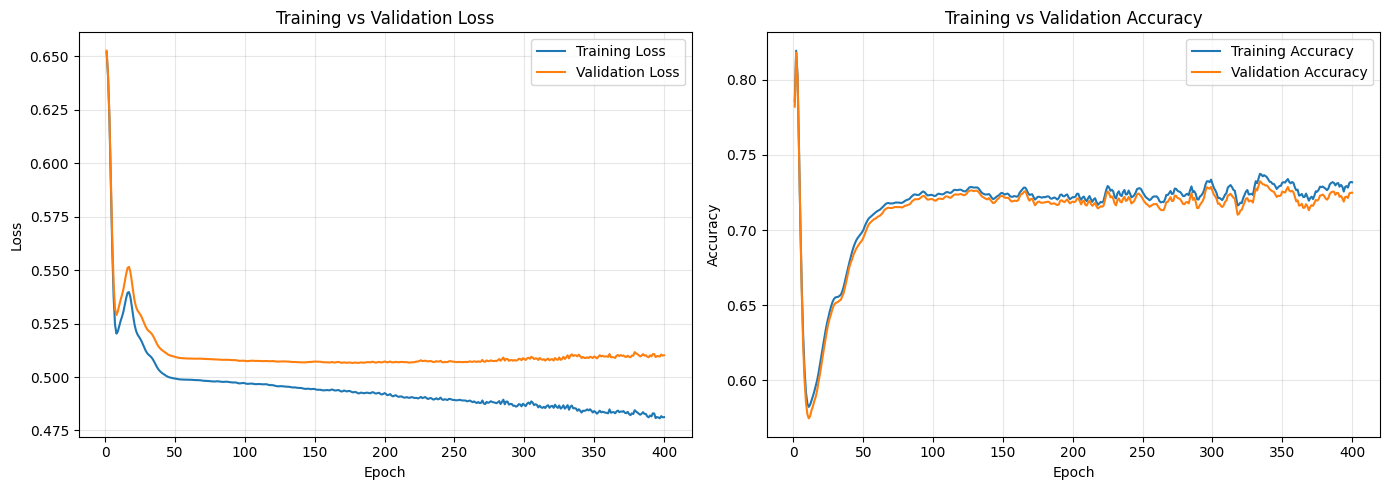

In [33]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
torch.save({
    "model_state_dict": model.state_dict(),
    "input_dim": INPUT_DIM,
    "lr": LEARNING_RATE,
    "epochs": EPOCHS,
}, "deep_mlp.pth")

print("Model saved successfully!")

Model saved successfully!


## Evaluation part 1 (Validation set)

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Make sure we use the best model
model.eval()

with torch.no_grad():

    val_outputs = model(X_val_tensor)

    # Predicted classes
    val_predictions = torch.argmax(val_outputs, dim=1)

    # Probability of class 1
    val_probabilities = torch.softmax(
        val_outputs, dim=1
    )[:, 1]

# Move predictions and labels to CPU
y_val_true = y_val_tensor.cpu().numpy()
y_val_pred = val_predictions.cpu().numpy()
y_val_prob = val_probabilities.cpu().numpy()

# Calculate metrics
val_accuracy = accuracy_score(y_val_true, y_val_pred)

val_precision = precision_score(
    y_val_true, y_val_pred, zero_division=0
)

val_recall = recall_score(
    y_val_true, y_val_pred, zero_division=0
)

val_f1 = f1_score(
    y_val_true, y_val_pred, zero_division=0
)

val_auc = roc_auc_score(y_val_true, y_val_prob)

print("Validation Results")
print("------------------------------")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1-score:  {val_f1:.4f}")
print(f"ROC-AUC:   {val_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=["No Disease (0)", "Disease (1)"],
        zero_division=0
    )
)

Validation Results
------------------------------
Accuracy:  0.7248
Precision: 0.3020
Recall:    0.7776
F1-score:  0.4350
ROC-AUC:   0.8246

Classification Report:
                precision    recall  f1-score   support

No Disease (0)       0.95      0.72      0.82     21889
   Disease (1)       0.30      0.78      0.43      3453

      accuracy                           0.72     25342
     macro avg       0.63      0.75      0.63     25342
  weighted avg       0.86      0.72      0.77     25342



##Tune Hyperprameters

In [36]:

import itertools
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

tuning_results = []

global_best_val_loss = float("inf")
global_best_state = None
global_best_config = None

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed to make initialization comparable
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = DeepMLP(
            input_dim=INPUT_DIM,
        dropout=0.3
    ).to(device)

    criterion = make_criterion()

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None
    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)
        train_loss = criterion(train_outputs, y_train_tensor)

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():
            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Save best checkpoint for this configuration
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Update global best configuration
    if best_config_loss < global_best_val_loss:

        global_best_val_loss = best_config_loss

        global_best_state = copy.deepcopy(
            best_config_state
        )

        global_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nHyperparameter Tuning Results:")
display(tuning_df)

print("\nBest Configuration:")
print(global_best_config)
print(f"Best Validation Loss: {global_best_val_loss:.4f}")


Testing LR=0.001, Weight Decay=0
Best Epoch: 365 | Best Val Loss: 0.5079

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 364 | Best Val Loss: 0.5075

Testing LR=0.005, Weight Decay=0
Best Epoch: 179 | Best Val Loss: 0.5068

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 63 | Best Val Loss: 0.5094

Testing LR=0.01, Weight Decay=0
Best Epoch: 177 | Best Val Loss: 0.5066

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 44 | Best Val Loss: 0.5098

Hyperparameter Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0000,177,0.506590
1,0.005,0.0000,179,0.506824
2,0.001,0.0001,364,0.507522
3,0.001,0.0000,365,0.507913
4,0.005,0.0001,63,0.509350
5,0.010,0.0001,44,0.509776



Best Configuration:
{'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 177}
Best Validation Loss: 0.5066


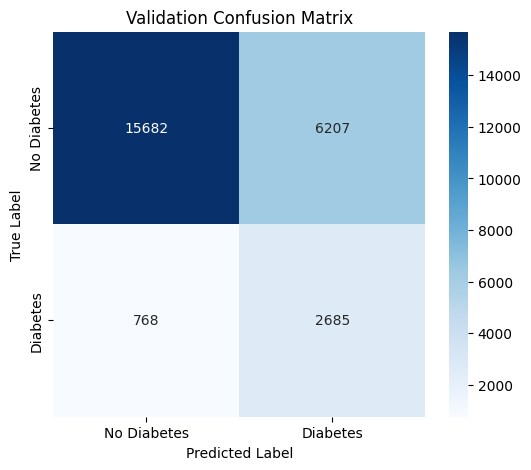

In [37]:
cm = confusion_matrix(y_val_true, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Validation Confusion Matrix")

plt.show()

In [38]:
model = DeepMLP(
            input_dim=INPUT_DIM,
    dropout=0.3
).to(device)

model.load_state_dict(global_best_state)
model.eval()

print("Best tuned model loaded successfully!")
print("Configuration:", global_best_config)

Best tuned model loaded successfully!
Configuration: {'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 177}


In [39]:
torch.save({
    "model_state_dict": model.state_dict(),
    "best_config": global_best_config,
    "best_val_loss": global_best_val_loss,
    "input_dim":INPUT_DIM,
    "dropout": 0.3
}, "best_tuned_Deep_MLP.pth")

print("Tuned model saved successfully!")

Tuned model saved successfully!


## Baseline (Shallow MLP)

In [40]:
#================
# Baseline Model Architecture
#================

class ShallowMLP(nn.Module):
    def __init__(self, input_dim, hidden=32):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_dim, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, x):
        return self.network(x)


print("Trainable parameters:")
print("Baseline MLP:", count_params(ShallowMLP(INPUT_DIM)))
print("Deep MLP:    ", count_params(model))

Trainable parameters:
Baseline MLP: 770
Deep MLP:     13666


In [41]:

#================
# Baseline Model Training & Tuning
#================

baseline_best_train_history = None
baseline_best_val_history = None

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

baseline_tuning_results = []

baseline_best_val_loss = float("inf")
baseline_best_state = None
baseline_best_config = None

criterion = make_criterion()

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed for comparable initialization
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = ShallowMLP(
        input_dim=X_train_tensor.shape[1]
    ).to(device)

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None

    # Track loss for this configuration
    train_history = []
    val_history = []

    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)

        train_loss = criterion(
            train_outputs,
            y_train_tensor
        )

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():

            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Record epoch losses
        train_history.append(train_loss.item())
        val_history.append(val_loss)

        # Save best checkpoint
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    baseline_tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Keep the best configuration and its histories
    if best_config_loss < baseline_best_val_loss:

        baseline_best_val_loss = best_config_loss

        baseline_best_state = copy.deepcopy(
            best_config_state
        )

        baseline_best_train_history = train_history.copy()
        baseline_best_val_history = val_history.copy()

        baseline_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display tuning results
baseline_tuning_df = pd.DataFrame(
    baseline_tuning_results
).sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nBaseline Tuning Results:")
display(baseline_tuning_df)

print("\nBest Baseline Configuration:")
print(baseline_best_config)

print(f"Best Validation Loss: {baseline_best_val_loss:.4f}")



Testing LR=0.001, Weight Decay=0
Best Epoch: 400 | Best Val Loss: 0.5113

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 400 | Best Val Loss: 0.5114

Testing LR=0.005, Weight Decay=0
Best Epoch: 368 | Best Val Loss: 0.5081

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 400 | Best Val Loss: 0.5078

Testing LR=0.01, Weight Decay=0
Best Epoch: 213 | Best Val Loss: 0.5082

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 321 | Best Val Loss: 0.5071

Baseline Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0001,321,0.507121
1,0.005,0.0001,400,0.507814
2,0.005,0.0000,368,0.508140
3,0.010,0.0000,213,0.508150
4,0.001,0.0000,400,0.511280
5,0.001,0.0001,400,0.511423



Best Baseline Configuration:
{'learning_rate': 0.01, 'weight_decay': 0.0001, 'best_epoch': 321}
Best Validation Loss: 0.5071


In [42]:
#================
# Load Best Baseline Model
#================

baseline_model = ShallowMLP(INPUT_DIM).to(device)
baseline_model.load_state_dict(baseline_best_state)
baseline_model.eval()

print("Best baseline model loaded:", baseline_best_config)

Best baseline model loaded: {'learning_rate': 0.01, 'weight_decay': 0.0001, 'best_epoch': 321}


## Evaluation

In [43]:
#================
# Final Test Evaluation — Model Comparison
#================

model.eval()
baseline_model.eval()

with torch.no_grad():

    # Deep MLP
    deep_outputs = model(X_test_tensor)

    deep_probabilities = torch.softmax(
        deep_outputs, dim=1
    )[:, 1]

    deep_predictions = torch.argmax(
        deep_outputs, dim=1
    )

    # Shallow MLP baseline
    baseline_outputs = baseline_model(X_test_tensor)

    baseline_probabilities = torch.softmax(
        baseline_outputs, dim=1
    )[:, 1]

    baseline_predictions = torch.argmax(
        baseline_outputs, dim=1
    )


# Convert to NumPy
y_test_true = y_test_tensor.cpu().numpy()

deep_pred = deep_predictions.cpu().numpy()
deep_prob = deep_probabilities.cpu().numpy()

baseline_pred = baseline_predictions.cpu().numpy()
baseline_prob = baseline_probabilities.cpu().numpy()


# Calculate metrics
def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


y_test_true = y_test_tensor.cpu().numpy()

deep_pred, deep_prob = predict(model, X_test_tensor)
baseline_pred, baseline_prob = predict(baseline_model, X_test_tensor)

deep_metrics = compute_metrics(y_test_true, deep_pred, deep_prob)
baseline_metrics = compute_metrics(y_test_true, baseline_pred, baseline_prob)

comparison = pd.DataFrame({
    "Metric": list(deep_metrics),
    "Shallow MLP Baseline": list(baseline_metrics.values()),
    "Deep MLP": list(deep_metrics.values()),
})
comparison["Difference"] = comparison["Deep MLP"] - comparison["Shallow MLP Baseline"]

majority_acc = max(y_test_true.mean(), 1 - y_test_true.mean())

print("FINAL TEST RESULTS")
print("=" * 55)
print(f"Majority-class accuracy (always predict the common class): {majority_acc:.4f}\n")
display(comparison.round(4))

FINAL TEST RESULTS
Majority-class accuracy (always predict the common class): 0.8655



,Metric,Shallow MLP Baseline,Deep MLP,Difference
0,Accuracy,0.7217,0.7211,-0.0006
1,Balanced Accuracy,0.7493,0.7519,0.0026
2,Precision,0.2978,0.2984,0.0005
3,Recall,0.7871,0.7941,0.0070
4,F1-score,0.4321,0.4337,0.0016
5,ROC-AUC,0.8261,0.8268,0.0007
6,PR-AUC,0.4186,0.4198,0.0012


In [44]:
for name, pred in [("Shallow MLP Baseline", baseline_pred), ("Deep MLP", deep_pred)]:
    print(f"\n{name} - Test set")
    print(classification_report(y_test_true, pred, target_names=CLASS_NAMES, zero_division=0))


Shallow MLP Baseline - Test set
              precision    recall  f1-score   support

 No Diabetes       0.96      0.71      0.82     22121
    Diabetes       0.30      0.79      0.43      3438

    accuracy                           0.72     25559
   macro avg       0.63      0.75      0.62     25559
weighted avg       0.87      0.72      0.76     25559


Deep MLP - Test set
              precision    recall  f1-score   support

 No Diabetes       0.96      0.71      0.82     22121
    Diabetes       0.30      0.79      0.43      3438

    accuracy                           0.72     25559
   macro avg       0.63      0.75      0.62     25559
weighted avg       0.87      0.72      0.76     25559



Deep MLP : threshold 0.62 (validation F1 0.4599)
Baseline : threshold 0.66 (validation F1 0.4603)


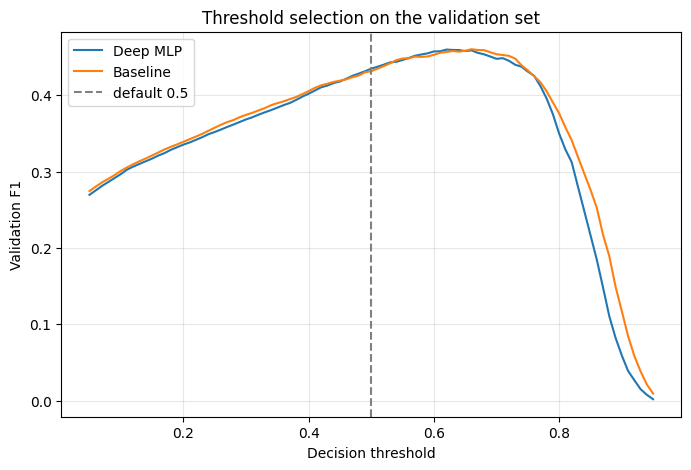

In [45]:
thresholds = np.arange(0.05, 0.96, 0.01)

def best_threshold(y_true, y_prob):
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    i = int(np.argmax(scores))
    return float(thresholds[i]), scores[i], scores

y_val_true = y_val_tensor.cpu().numpy()
_, deep_val_prob = predict(model, X_val_tensor)
_, baseline_val_prob = predict(baseline_model, X_val_tensor)

deep_thr, deep_val_f1, deep_scores = best_threshold(y_val_true, deep_val_prob)
base_thr, base_val_f1, base_scores = best_threshold(y_val_true, baseline_val_prob)

print(f"Deep MLP : threshold {deep_thr:.2f} (validation F1 {deep_val_f1:.4f})")
print(f"Baseline : threshold {base_thr:.2f} (validation F1 {base_val_f1:.4f})")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, deep_scores, label="Deep MLP")
plt.plot(thresholds, base_scores, label="Baseline")
plt.axvline(0.5, linestyle="--", color="gray", label="default 0.5")
plt.xlabel("Decision threshold")
plt.ylabel("Validation F1")
plt.title("Threshold selection on the validation set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
deep_pred_t, _ = predict(model, X_test_tensor, threshold=deep_thr)
baseline_pred_t, _ = predict(baseline_model, X_test_tensor, threshold=base_thr)

rows = {
    "Deep MLP (0.50)": compute_metrics(y_test_true, deep_pred, deep_prob),
    f"Deep MLP ({deep_thr:.2f})": compute_metrics(y_test_true, deep_pred_t, deep_prob),
    "Baseline (0.50)": compute_metrics(y_test_true, baseline_pred, baseline_prob),
    f"Baseline ({base_thr:.2f})": compute_metrics(y_test_true, baseline_pred_t, baseline_prob),
}
display(pd.DataFrame(rows).T.round(4))

for name, pred in [(f"Deep MLP @ {deep_thr:.2f}", deep_pred_t),
                   (f"Baseline @ {base_thr:.2f}", baseline_pred_t)]:
    print(f"\n{name} - Test set")
    print(confusion_matrix(y_test_true, pred))
    print(classification_report(y_test_true, pred, target_names=CLASS_NAMES, zero_division=0))

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Deep MLP (0.50),0.7211,0.7519,0.2984,0.7941,0.4337,0.8268,0.4198
Deep MLP (0.62),0.8019,0.7283,0.3632,0.6277,0.4601,0.8268,0.4198
Baseline (0.50),0.7217,0.7493,0.2978,0.7871,0.4321,0.8261,0.4186
Baseline (0.66),0.8113,0.7189,0.3731,0.5925,0.4579,0.8261,0.4186



Deep MLP @ 0.62 - Test set
[[18337  3784]
 [ 1280  2158]]
              precision    recall  f1-score   support

 No Diabetes       0.93      0.83      0.88     22121
    Diabetes       0.36      0.63      0.46      3438

    accuracy                           0.80     25559
   macro avg       0.65      0.73      0.67     25559
weighted avg       0.86      0.80      0.82     25559


Baseline @ 0.66 - Test set
[[18698  3423]
 [ 1401  2037]]
              precision    recall  f1-score   support

 No Diabetes       0.93      0.85      0.89     22121
    Diabetes       0.37      0.59      0.46      3438

    accuracy                           0.81     25559
   macro avg       0.65      0.72      0.67     25559
weighted avg       0.86      0.81      0.83     25559



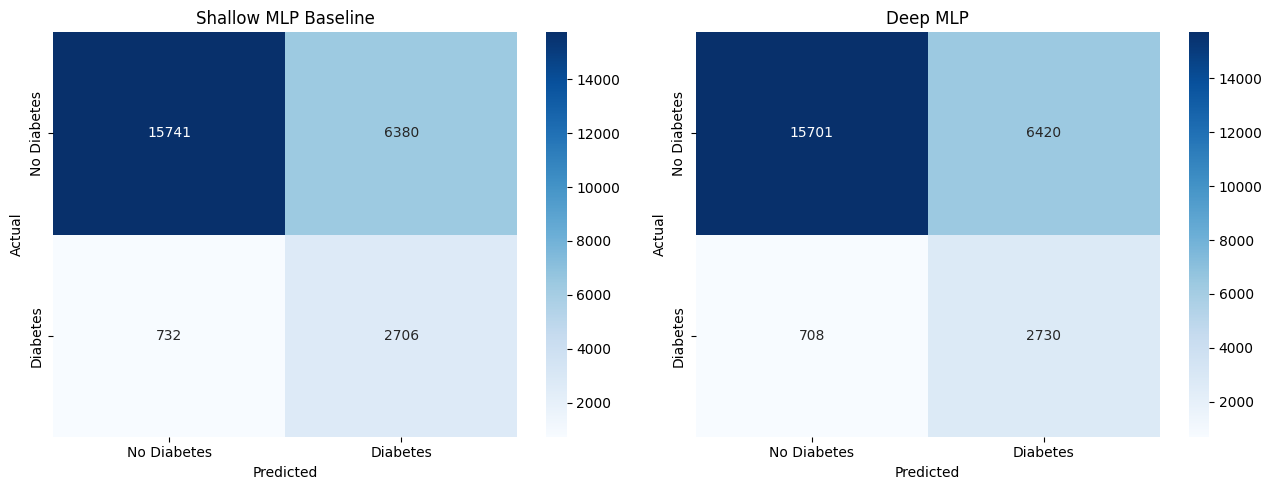

In [47]:
#================
# Confusion Matrix Comparison
#================

baseline_cm = confusion_matrix(
    y_test_true, baseline_pred
)

deep_cm = confusion_matrix(
    y_test_true, deep_pred
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("Shallow MLP Baseline")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("Deep MLP")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

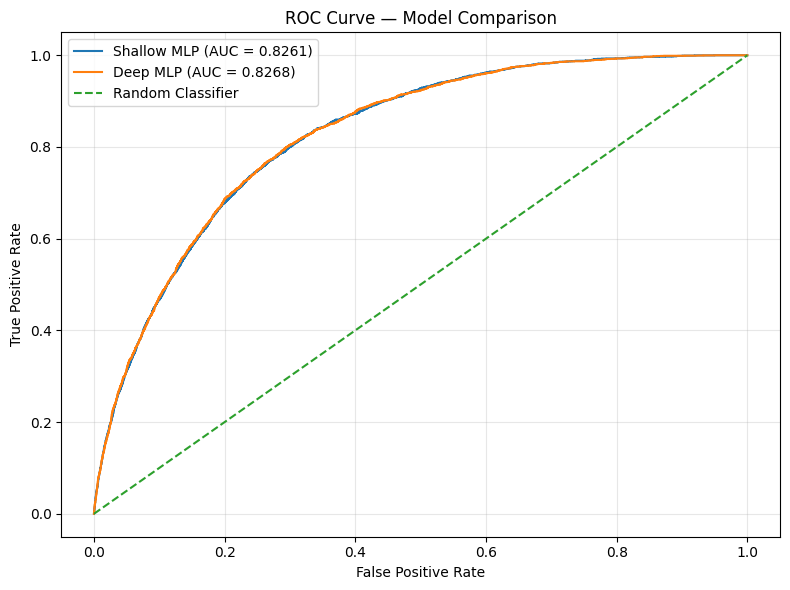

In [48]:
#================
# ROC Curve Comparison
#================

baseline_fpr, baseline_tpr, _ = roc_curve(
    y_test_true, baseline_prob
)

deep_fpr, deep_tpr, _ = roc_curve(
    y_test_true, deep_prob
)

baseline_auc = roc_auc_score(
    y_test_true, baseline_prob
)

deep_auc = roc_auc_score(
    y_test_true, deep_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f"Shallow MLP (AUC = {baseline_auc:.4f})"
)

plt.plot(
    deep_fpr,
    deep_tpr,
    label=f"Deep MLP (AUC = {deep_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()